# PROJECT 1: BANK MARKETING — TERM DEPOSIT SUBSCRIPTION PREDICTION

## 1. Introduction and Problem Formulation

### 1.1 Background

Telephone marketing campaigns are commonly used by financial institutions to promote products and services. However, contacting customers who are unlikely to subscribe can increase operational costs and reduce marketing efficiency.

This project uses a dataset of telephone marketing campaigns conducted by a Portuguese banking institution to develop and evaluate machine learning models for predicting whether a customer will subscribe to a term deposit.

### 1.2 Problem Statement

The bank needs to identify customers who are more likely to subscribe to a term deposit before initiating marketing calls. This is a binary classification problem in which the target variable, `y`, indicates whether a customer subscribed (`yes`) or did not subscribe (`no`).

The analysis will compare predictive approaches and recommend a decision threshold that balances unnecessary marketing calls against missed potential subscribers.

### 1.3 Objectives

The specific objectives are to:

1. Explore the dataset, identify data quality issues, and undertake appropriate data preparation.
2. Establish a majority-class baseline and compare up to three classification approaches.
3. Evaluate and rank the models using appropriate performance metrics and validation procedures.
4. Recommend a classification threshold based on the trade-off between unnecessary calls and missed subscribers.

### 1.4 Analytical Approach

The project will follow a structured machine learning workflow comprising exploratory data analysis, data preparation, baseline establishment, model development, evaluation, and threshold selection.

Particular attention will be given to class imbalance, potential data leakage, model generalization, and the practical implications of prediction errors.

In [1]:
#Importing libraries for data manipulation and analysis
import pandas as pd
import numpy as np

#For visualization
import matplotlib.pyplot as plt
import seaborn as sns

#Configuring display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

#Configuring visualization
sns.set_theme(style="whitegrid")

In [2]:
#Importing libraries for data manipulation and analysis
import pandas as pd
import numpy as np

#For visualization
import matplotlib.pyplot as plt
import seaborn as sns

#Configuring display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

#Configuring visualization
sns.set_theme(style="whitegrid")


In [3]:
# Loading dataset
df = pd.read_csv("bank-additional-full.csv", sep=";")

df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
#Sgape of dataset
print("Dataset dimensions:", df.shape)

#Variable names
print("\nColumn names:")
print(df.columns.tolist())

# Examining data types and non-null values
print("\nDataset information:")
df.info()

Dataset dimensions: (41188, 21)

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  

In [5]:
#Generating descriptive statistics for numerical variables
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


In [6]:
#Examining the distribution of the target variable

target_counts = df["y"].value_counts()

target_percentages = (
    df["y"].value_counts(normalize=True) * 100
).round(2)

target_distribution = pd.DataFrame({
    "Frequency": target_counts,
    "Percentage (%)": target_percentages
})

display(target_distribution)

,Frequency,Percentage (%)
y,,
no,36548,88.73
yes,4640,11.27


In [ ]:
#Checking conventional missing values
missing_values = df.isnull().sum()

print("Total conventional missing values:")
print(missing_values.sum())

#Identifying 'unknown' values in categorical variables
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

unknown_counts = (
    df[categorical_columns]
    .eq("unknown")
    .sum()
    .sort_values(ascending=False)
)

unknown_percentages = (
    unknown_counts / len(df) * 100
).round(2)

unknown_summary = pd.DataFrame({
    "Unknown Count": unknown_counts,
    "Unknown Percentage (%)": unknown_percentages
})

display(unknown_summary)

Total conventional missing values:
0


,Unknown Count,Unknown Percentage (%)
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19
contact,0,0.00
month,0,0.00
day_of_week,0,0.00
poutcome,0,0.00


In [9]:
#Identifying exact duplicate observations

duplicate_count = df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / len(df) * 100
)

print(f"Number of duplicate rows: {duplicate_count}")

print(
    f"Percentage of duplicate rows: "
    f"{duplicate_percentage:.4f}%"
)

Number of duplicate rows: 12
Percentage of duplicate rows: 0.0291%


2.2 Preliminary Exploratory Data Analysis Findings

The dataset comprises 41,188 observations and 21 variables, including 10 numerical and 11 categorical variables. Descriptive statistics indicate that customers have a mean age of 40.02 years, ranging from 17 to 98 years. The number of contacts during the current campaign averages 2.57, with a maximum of 56, suggesting a positively skewed distribution.

The target variable exhibits substantial class imbalance: 36,548 customers (88.73%) did not subscribe to a term deposit, compared with 4,640 (11.27%) who subscribed. Consequently, a majority-class classifier would achieve 88.73% accuracy without identifying any subscribers. This finding justifies evaluating predictive performance using metrics beyond accuracy, particularly precision, recall, F1-score, and precision-recall AUC.

No conventional missing values were identified. However, six categorical variables contain observations coded as "unknown", particularly credit-default status (20.87%) and education (4.20%). These categories will initially be retained to avoid unnecessary information loss, with alternative treatments considered during robustness analysis.

Twelve exact duplicate observations (0.0291%) were identified. Given their negligible frequency and the absence of unique customer identifiers, they will initially be retained, with their potential influence assessed through sensitivity analysis.

Two variables require special consideration. The variable pdays uses 999 to indicate no previous contact and should therefore not be interpreted as an ordinary continuous measurement. Additionally, duration measures call length and is unavailable before contacting a customer. It will be excluded from the primary predictive model to prevent the use of information unavailable at the intended prediction time.

These findings inform subsequent feature engineering, model selection, validation, and performance evaluation.

In [10]:
#Calculating subscription rates by job category

job_subscription = (
    df.groupby("job")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

display(job_subscription.round(2))

job
student          31.43
retired          25.23
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.89
Name: y, dtype: float64

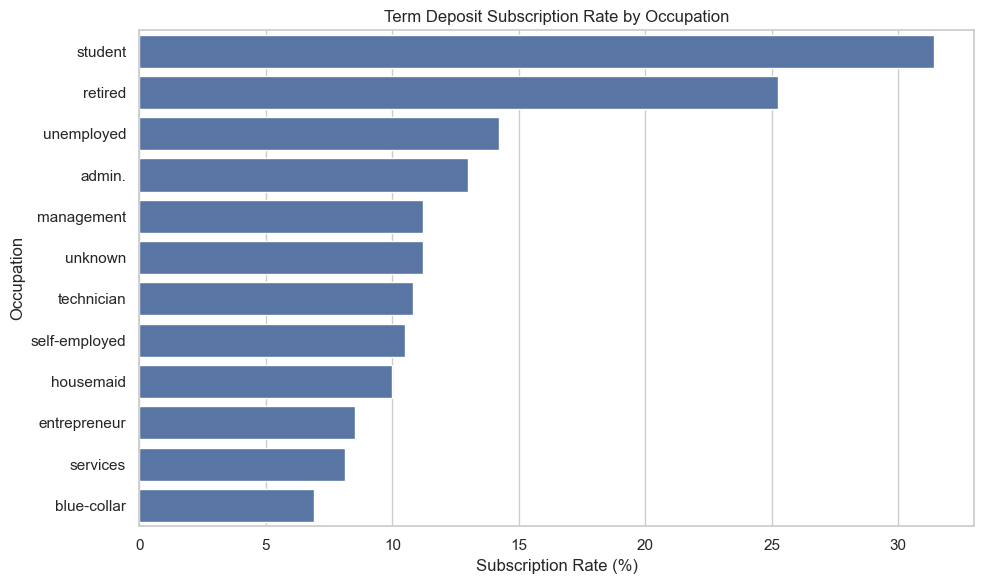

In [ ]:
#Visualising subscription rates by occupation

plt.figure(figsize=(10, 6))

sns.barplot(
    x=job_subscription.values,
    y=job_subscription.index
)

plt.title("Term Deposit Subscription Rate by Occupation")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Occupation")

plt.tight_layout()
plt.show()

In [12]:
# Calculating subscription rates by previous campaign outcome

previous_outcome_subscription = (
    df.groupby("poutcome")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

display(previous_outcome_subscription.round(2))

poutcome
success        65.11
failure        14.23
nonexistent     8.83
Name: y, dtype: float64

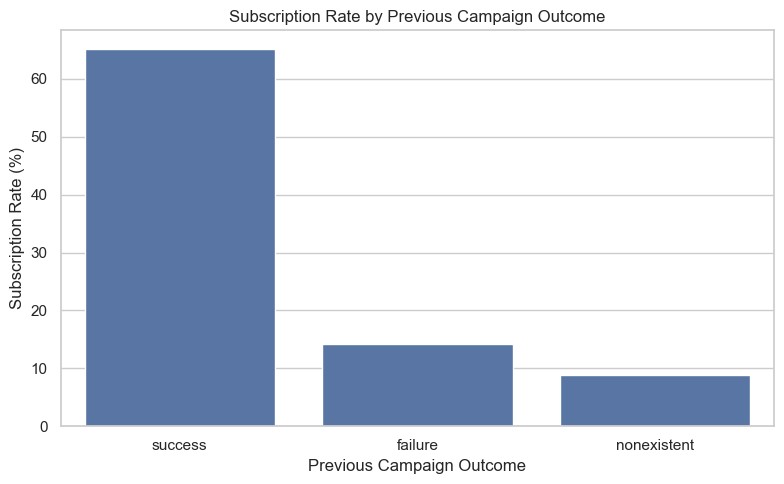

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=previous_outcome_subscription.index,
    y=previous_outcome_subscription.values
)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")

plt.tight_layout()
plt.show()

In [14]:
#Creating age groups for exploratory analysis

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        "Under 25",
        "25-34",
        "35-44",
        "45-54",
        "55-64",
        "65+"
    ],
    right=False
)

# Calculating subscription rates by age group

age_subscription = (
    df.groupby("age_group", observed=True)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

display(age_subscription.round(2))

age_group
Under 25    23.97
25-34       12.17
35-44        8.65
45-54        8.65
55-64       13.57
65+         47.21
Name: y, dtype: float64

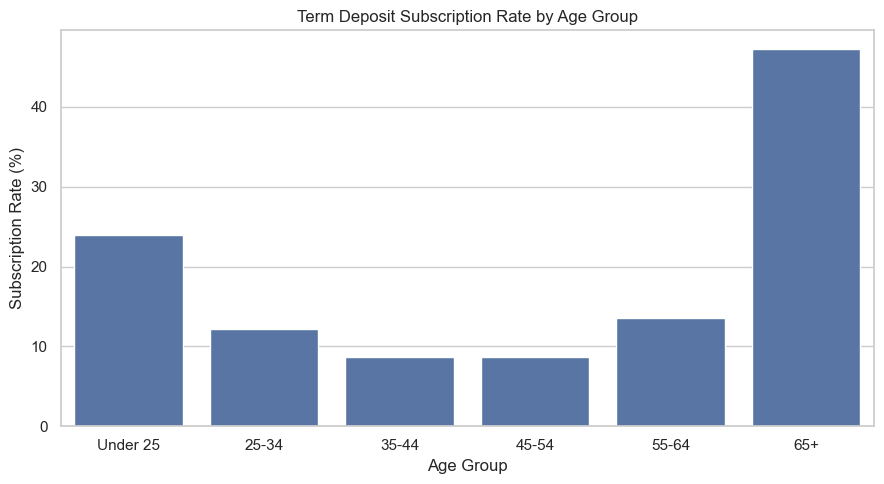

In [15]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_subscription.index,
    y=age_subscription.values
)

plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")

plt.tight_layout()
plt.show()

### 2.4 Bivariate Analysis Findings

Bivariate analysis revealed notable differences in term-deposit subscription rates across customer characteristics.

Occupation was associated with subscription, with students (31.43%) and retired customers (25.23%) recording the highest subscription rates, compared with 6.89% among blue-collar workers.

Previous campaign outcome exhibited a particularly strong association with subscription. Customers with previously successful campaign outcomes recorded a subscription rate of 65.11%, compared with 14.23% among those with previous failures and 8.83% among customers without recorded previous campaign outcomes.

Age-group analysis suggested a nonlinear relationship with subscription. Customers aged 65 years and above recorded the highest subscription rate (47.21%), followed by those below 25 years (23.97%). Subscription rates were lowest among customers aged 35–54 years (8.65%).

These findings suggest that occupation, age, and previous campaign outcomes may provide useful predictive information. The apparent nonlinear relationship between age and subscription also supports investigating models capable of capturing nonlinear patterns and interactions.

However, these are descriptive associations rather than causal effects, and their predictive usefulness must be evaluated using appropriate validation procedures.

In [16]:
#Examining group sizes and subscription rates

# Age groups
age_summary = (
    df.groupby("age_group", observed=True)
    .agg(
        Total_Customers=("y", "size"),
        Subscribers=("y", lambda x: (x == "yes").sum())
    )
)

age_summary["Subscription_Rate"] = (
    age_summary["Subscribers"] /
    age_summary["Total_Customers"] * 100
).round(2)

print("Subscription Summary by Age Group")
display(age_summary)


# Occupation
job_summary = (
    df.groupby("job")
    .agg(
        Total_Customers=("y", "size"),
        Subscribers=("y", lambda x: (x == "yes").sum())
    )
)

job_summary["Subscription_Rate"] = (
    job_summary["Subscribers"] /
    job_summary["Total_Customers"] * 100
).round(2)

print("Subscription Summary by Occupation")
display(job_summary)

Subscription Summary by Age Group


,Total_Customers,Subscribers,Subscription_Rate
age_group,,,
Under 25,1068,256,23.97
25-34,13686,1666,12.17
35-44,13500,1168,8.65
45-54,8704,753,8.65
55-64,3567,484,13.57
65+,663,313,47.21


Subscription Summary by Occupation


,Total_Customers,Subscribers,Subscription_Rate
job,,,
admin.,10422,1352,12.97
blue-collar,9254,638,6.89
entrepreneur,1456,124,8.52
housemaid,1060,106,10.00
management,2924,328,11.22
retired,1720,434,25.23
self-employed,1421,149,10.49
services,3969,323,8.14
student,875,275,31.43


### 2.5 Group Size and Subscription Volume

Further analysis revealed differences between subscription rates and absolute subscriber volumes. Customers aged 65 years and above recorded the highest subscription rate (47.21%) but contributed only 313 subscribers from 663 observations. Conversely, customers aged 25–34 contributed the largest number of subscribers (1,666), despite a lower subscription rate of 12.17%.

Similarly, students recorded the highest occupational subscription rate (31.43%), while administrative workers contributed the largest number of subscribers (1,352), representing approximately 29.14% of all subscriptions.

These findings demonstrate the importance of considering both subscription probability and customer-group size when evaluating marketing opportunities. However, descriptive group-level differences do not establish individual predictive performance and must be assessed through validated classification models.

## 3. Data Preparation

Data preparation was undertaken to ensure that the predictors were suitable for classification while minimizing information leakage and preserving potentially useful observations.

The process involved identifying variables unavailable at prediction time, handling special numerical codes, retaining informative categorical values, separating predictors from the target variable, and establishing independent training and testing datasets.

Preprocessing transformations requiring parameter estimation will be fitted exclusively on the training data and subsequently applied to validation and test observations.

In [17]:
#Creating a separate dataset for modeling
df_model = df.copy()

#Removing call duration because it is unavailable before a call
df_model = df_model.drop(columns=["duration"])

#Remove age_group, which was created only for EDA
df_model = df_model.drop(columns=["age_group"])

print("Modeling dataset dimensions:", df_model.shape)

Modeling dataset dimensions: (41188, 20)


In [18]:
#Creating an indicator for previous contact
df_model["previously_contacted"] = (
    df_model["pdays"] != 999
).astype(int)

#Replacing the special code with a missing value
df_model["days_since_previous_contact"] = (
    df_model["pdays"].replace(999, np.nan)
)

#Removing the original pdays variable
df_model = df_model.drop(columns=["pdays"])

#inspecting new features
display(
    df_model[
        ["previously_contacted", "days_since_previous_contact"]
    ].head(10)
)

,previously_contacted,days_since_previous_contact
0,0,NaN
1,0,NaN
2,0,NaN
3,0,NaN
4,0,NaN
5,0,NaN
6,0,NaN
7,0,NaN
8,0,NaN
9,0,NaN


In [19]:
# Exclude current-call and campaign-related variables to avoid relying on information that may only become available during the current campaign
df_model = df_model.drop(
    columns=["contact", "month", "day_of_week", "campaign"]
)

# Separating predictors and target
X = df_model.drop(columns=["y"])

# Converting target into binary values
# 1 = subscribed, 0 = did not subscribe
y = df_model["y"].map({"yes": 1, "no": 0})

print("Predictor dimensions:", X.shape)
print("Target dimensions:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Predictor dimensions: (41188, 16)
Target dimensions: (41188,)

Target distribution:
y
0    36548
1     4640
Name: count, dtype: int64


In [20]:
from sklearn.model_selection import train_test_split

# Spliting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining subscription rate:")
print(y_train.mean().round(4))

print("\nTesting subscription rate:")
print(y_test.mean().round(4))

Training observations: 32950
Testing observations: 8238

Training subscription rate:
0.1127

Testing subscription rate:
0.1126


In [21]:
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Initialize majority-class classifier
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train baseline model
baseline_model.fit(X_train, y_train)

# Generate predictions
baseline_predictions = baseline_model.predict(X_test)

# Evaluate baseline performance
baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_precision = precision_score(
    y_test, baseline_predictions,
    zero_division=0
)

baseline_recall = recall_score(
    y_test, baseline_predictions,
    zero_division=0
)

baseline_f1 = f1_score(
    y_test, baseline_predictions,
    zero_division=0
)

print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

Accuracy:  0.8874
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Confusion Matrix:
[[7310    0]
 [ 928    0]]


### 3.1 Data Preparation and Train-Test Split

The dataset was prepared for binary classification by encoding the target variable as 1 for subscribers and 0 for non-subscribers. Variables unavailable at the intended prediction time were excluded to minimize information leakage. The special value 999 in `pdays` was separated into an indicator of previous contact and a variable representing days since the previous contact.

The resulting predictor matrix contained 41,188 observations and 16 variables. The data was partitioned into training (80%) and testing (20%) subsets using stratified random sampling with a fixed random seed of 42. This produced 32,950 training observations and 8,238 testing observations, with subscription rates of 11.27% and 11.26%, respectively.

The stratified split preserved the original class distribution, ensuring that both subsets contained representative proportions of subscribers and non-subscribers. The test set was designated for final evaluation, while model development and selection would be conducted using the training data.

### 3.2 Majority-Class Baseline

A majority-class classifier was established using the `DummyClassifier` algorithm with the `most_frequent` strategy. The classifier predicted the majority class (non-subscription) for every observation.

The baseline achieved an accuracy of 88.74%, but precision, recall, and F1-score were all zero. Examination of the confusion matrix revealed that the classifier correctly identified 7,310 non-subscribers but failed to identify any of the 928 actual subscribers.

These results demonstrate that accuracy alone is misleading when evaluating models on imbalanced datasets. Although the baseline achieves high accuracy, it provides no practical value for identifying potential subscribers.

Consequently, subsequent classification models will be evaluated using precision, recall, F1-score, ROC-AUC, and precision-recall AUC, with particular emphasis on their ability to identify subscribers while minimizing unnecessary marketing calls.

## 4. Model Development and Selection

Three classification approaches were selected for comparison: Logistic Regression, Random Forest, and Gradient Boosting. These approaches represent interpretable linear classification, bagging-based ensemble learning, and boosting-based ensemble learning, respectively.

To ensure methodological consistency, preprocessing transformations will be implemented using scikit-learn pipelines. Numerical variables will undergo median imputation and standardization, while categorical variables will undergo most-frequent imputation where necessary and one-hot encoding.

All preprocessing parameters will be estimated exclusively from the training folds during cross-validation to minimize data leakage.

In [22]:
# Identifying numerical and categorical predictors

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['age', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'days_since_previous_contact']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome']

Number of numerical features: 9
Number of categorical features: 7


In [23]:
#Building the preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


# Numerical preprocessing pipeline
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)


# Categorical preprocessing pipeline
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)


# Combine preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [24]:
#Verifying the preprocessing pipeline 

X_train_processed = preprocessor.fit_transform(X_train)

print("Original training dimensions:", X_train.shape)

print(
    "Processed training dimensions:",
    X_train_processed.shape
)

print(
    "Number of features after preprocessing:",
    X_train_processed.shape[1]
)

Original training dimensions: (32950, 16)
Processed training dimensions: (32950, 45)
Number of features after preprocessing: 45


### 4.1 Logistic Regression

Logistic Regression was selected as the first classification approach because it provides an interpretable probabilistic model for binary outcomes. The algorithm models the log-odds of subscription as a linear combination of predictor variables.

Its inclusion provides a useful benchmark for evaluating whether more complex nonlinear algorithms offer meaningful improvements in predictive performance.

The model was implemented within a preprocessing pipeline to ensure that numerical imputation, standardization, and categorical encoding are performed consistently and without information leakage during cross-validation.

In [25]:
# Importing Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


In [26]:
# Import cross-validation tools
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# Define stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

# Evaluate Logistic Regression
logistic_cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Summarize cross-validation results
logistic_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean Score": [
        logistic_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        logistic_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

display(logistic_summary.round(4))

,Metric,Mean Score,Standard Deviation
0,accuracy,0.8988,0.0013
1,precision,0.6798,0.0246
2,recall,0.1937,0.0066
3,f1,0.3014,0.0083
4,roc_auc,0.7626,0.0046
5,pr_auc,0.4230,0.0121


### 4.1.1 Logistic Regression Performance Evaluation

Logistic Regression was evaluated using five-fold stratified cross-validation on the training dataset. The model achieved mean accuracy of 89.88%, precision of 67.98%, recall of 19.37%, F1-score of 30.14%, ROC-AUC of 76.26%, and average precision of 42.30%.

Although accuracy exceeded the majority-class baseline, the model demonstrated a substantial imbalance between precision and recall. Its relatively high precision indicates that customers classified as potential subscribers were frequently correctly identified. However, recall of 19.37% indicates that approximately 80.63% of actual subscribers were not identified at the default classification threshold of 0.5.

The ROC-AUC of 76.26% indicates moderate discriminatory ability, while average precision of 42.30% substantially exceeds the positive-class prevalence of approximately 11.27%.

Cross-validation standard deviations were relatively small, suggesting consistent performance across the five validation folds.

Overall, Logistic Regression provides a useful interpretable benchmark. However, its low recall suggests that alternative classification approaches or decision thresholds should be investigated to improve subscriber identification while maintaining acceptable precision.

### 4.2 Random Forest Classification

Random Forest was selected as the second classification approach because it can model nonlinear relationships and interactions between predictors without requiring these relationships to be specified in advance.

The algorithm combines predictions from multiple decision trees trained on bootstrap samples, with random subsets of predictors considered during tree construction. This approach can improve predictive stability and reduce overfitting relative to individual decision trees.

Random Forest was evaluated using the same five-fold stratified cross-validation strategy and performance metrics as Logistic Regression to ensure comparability.

In [27]:
# Importing Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

# Creating Random Forest pipeline
random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=1
        ))
    ]
)

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [28]:
# Evaluating Random Forest using the same cross-validation strategy
random_forest_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Summarizing Random Forest performance
random_forest_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean Score": [
        random_forest_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        random_forest_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

display(random_forest_summary.round(4))

,Metric,Mean Score,Standard Deviation
0,accuracy,0.8993,0.0014
1,precision,0.6771,0.0260
2,recall,0.2045,0.0103
3,f1,0.3138,0.0118
4,roc_auc,0.7889,0.0043
5,pr_auc,0.4447,0.0099


### 4.2.1 Random Forest Performance Evaluation

Random Forest was evaluated using five-fold stratified cross-validation, producing mean accuracy of 89.93%, precision of 67.71%, recall of 20.45%, F1-score of 31.38%, ROC-AUC of 78.89%, and average precision of 44.47%.

Compared with Logistic Regression, Random Forest demonstrated improvements in accuracy, recall, F1-score, ROC-AUC, and average precision. The largest improvements were observed in ROC-AUC (2.63 percentage points) and average precision (2.17 percentage points), suggesting improved discrimination between subscribers and non-subscribers.

However, precision declined marginally from 67.98% to 67.71%. Furthermore, recall remained relatively low, indicating that approximately 79.55% of actual subscribers were not identified at the default classification threshold.

The findings suggest that Random Forest captures predictive relationships not fully represented by Logistic Regression, potentially including nonlinear effects and interactions. Nevertheless, the observed improvements are modest, and further comparison with Gradient Boosting is necessary before establishing the final model ranking.

### 4.3 Gradient Boosting Classification

Gradient Boosting was selected as the third classification approach because of its ability to capture complex nonlinear relationships and interactions through sequential ensemble learning.

Unlike Random Forest, which aggregates independently constructed trees, Gradient Boosting iteratively builds new trees to reduce the predictive errors of the existing ensemble.

The algorithm was evaluated using the same five-fold stratified cross-validation procedure and performance metrics as Logistic Regression and Random Forest, ensuring methodological consistency and comparability.

In [ ]:
# Importing Gradient Boosting classifier
from sklearn.ensemble import GradientBoostingClassifier

# Create Gradient Boosting pipeline
gradient_boosting_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=3,
            min_samples_leaf=5,
            random_state=42
        ))
    ]
)

print("Gradient Boosting pipeline created successfully.")

Gradient Boosting pipeline created successfully.


In [30]:
# Evaluating Gradient Boosting using stratified cross-validation
gradient_boosting_cv_results = cross_validate(
    gradient_boosting_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Summarizing Gradient Boosting performance
gradient_boosting_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean Score": [
        gradient_boosting_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        gradient_boosting_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

display(gradient_boosting_summary.round(4))

,Metric,Mean Score,Standard Deviation
0,accuracy,0.8988,0.0016
1,precision,0.6652,0.0278
2,recall,0.2047,0.0117
3,f1,0.3129,0.0143
4,roc_auc,0.7890,0.0031
5,pr_auc,0.4443,0.0075


### 4.4 Comparative Evaluation and Ranking of Classification Models

Three classification approaches—Logistic Regression, Random Forest, and Gradient Boosting—were evaluated using five-fold stratified cross-validation on the training dataset. Performance was assessed using accuracy, precision, recall, F1-score, ROC-AUC, and Average Precision (AP).

Random Forest achieved the highest Average Precision (0.4447) and F1-score (0.3138), while Gradient Boosting recorded the highest ROC-AUC (0.7890) and recall (0.2047). Logistic Regression achieved the highest precision (0.6798) but demonstrated comparatively lower recall and discriminatory performance.

Given the substantial class imbalance, Average Precision was prioritized for model ranking because it summarizes precision-recall performance across decision thresholds. Based on this criterion, Random Forest ranked first, followed by Gradient Boosting and Logistic Regression.

However, the difference in Average Precision between Random Forest (0.4447) and Gradient Boosting (0.4443) was only 0.0004. Their ROC-AUC values were also nearly identical, indicating that the two ensemble approaches demonstrated broadly comparable predictive performance.

Although the ensemble models outperformed Logistic Regression on the principal ranking metric, all three approaches exhibited low recall at the default classification threshold of 0.5. This indicates that many potential subscribers remained unidentified.


In [31]:
# Combining cross-validation results into one table

model_results = {
    "Logistic Regression": logistic_cv_results,
    "Random Forest": random_forest_cv_results,
    "Gradient Boosting": gradient_boosting_cv_results
}

comparison_rows = []

for model_name, results in model_results.items():

    row = {"Model": model_name}

    for metric in scoring:

        row[metric] = results[f"test_{metric}"].mean()

    comparison_rows.append(row)

model_comparison = pd.DataFrame(comparison_rows)

# Rank models by Average Precision
model_comparison = model_comparison.sort_values(
    by="pr_auc",
    ascending=False
).reset_index(drop=True)

model_comparison.insert(
    0,
    "Rank",
    range(1, len(model_comparison) + 1)
)

display(model_comparison.round(4))

,Rank,Model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,1,Random Forest,0.8993,0.6771,0.2045,0.3138,0.7889,0.4447
1,2,Gradient Boosting,0.8988,0.6652,0.2047,0.3129,0.7890,0.4443
2,3,Logistic Regression,0.8988,0.6798,0.1937,0.3014,0.7626,0.4230


,Logistic Regression,Random Forest,Gradient Boosting
0,0.4441,0.4635,0.4586
1,0.4259,0.4433,0.4428
2,0.4199,0.4352,0.4420
3,0.4179,0.4379,0.4363
4,0.4075,0.4438,0.4417


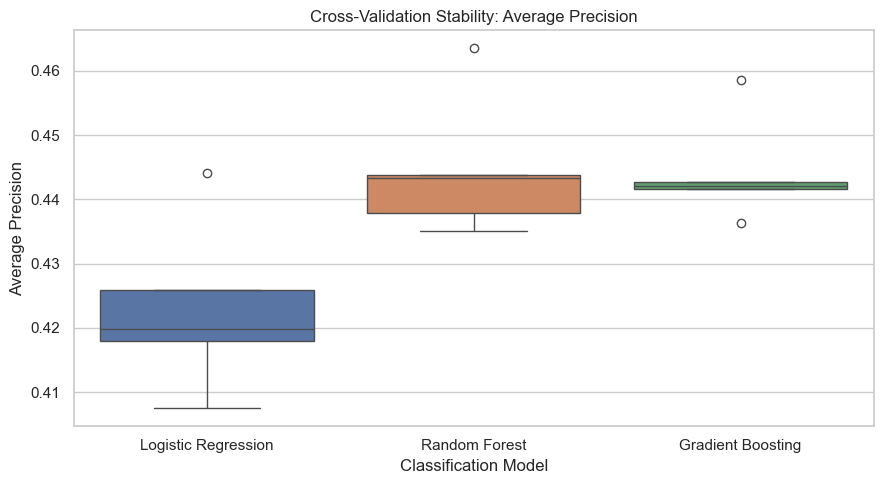

In [32]:
# Comparing Average Precision across cross-validation folds

cv_ap_comparison = pd.DataFrame({
    "Logistic Regression":
        logistic_cv_results["test_pr_auc"],

    "Random Forest":
        random_forest_cv_results["test_pr_auc"],

    "Gradient Boosting":
        gradient_boosting_cv_results["test_pr_auc"]
})

# Displaying fold-level results
display(cv_ap_comparison.round(4))

# Visualizing performance stability
plt.figure(figsize=(9, 5))

sns.boxplot(data=cv_ap_comparison)

plt.title("Cross-Validation Stability: Average Precision")
plt.ylabel("Average Precision")
plt.xlabel("Classification Model")

plt.tight_layout()
plt.show()

### 4.5 Cross-Validation Stability and Model Ranking

The consistency of model performance was examined using Average Precision scores across the five stratified cross-validation folds.

Random Forest achieved higher Average Precision than Gradient Boosting in four of the five folds, while Gradient Boosting performed better in one fold. Both ensemble approaches outperformed Logistic Regression across all five folds.

Gradient Boosting demonstrated the lowest standard deviation in Average Precision (0.0075), followed by Random Forest (0.0099) and Logistic Regression (0.0121), suggesting comparatively lower variability across validation folds.

Although Random Forest achieved the highest mean Average Precision (0.4447), its advantage over Gradient Boosting (0.4443) was negligible. Therefore, the two ensemble approaches were considered broadly comparable in predictive performance.

Based on the predefined ranking criterion of Average Precision, Random Forest was provisionally ranked first, Gradient Boosting second, and Logistic Regression third. However, this ranking should not be interpreted as demonstrating statistically significant superiority, particularly between the two ensemble models.

Random Forest was selected for further threshold analysis, while Gradient Boosting remained a competitive alternative.

In [33]:
# Examining sensitivity to Random Forest tree depth

depth_results = []

for depth in [6, 12, 18]:

    rf_pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", RandomForestClassifier(
                n_estimators=200,
                max_depth=depth,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=1
            ))
        ]
    )

    scores = cross_validate(
        rf_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "pr_auc": "average_precision",
            "roc_auc": "roc_auc",
            "f1": "f1"
        },
        n_jobs=-1
    )

    depth_results.append({
        "Max Depth": depth,
        "Mean AP": scores["test_pr_auc"].mean(),
        "AP Std": scores["test_pr_auc"].std(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "F1-score": scores["test_f1"].mean()
    })

depth_comparison = pd.DataFrame(depth_results)

display(depth_comparison.round(4))

,Max Depth,Mean AP,AP Std,ROC-AUC,F1-score
0,6,0.4398,0.0092,0.7850,0.2898
1,12,0.4447,0.0099,0.7889,0.3138
2,18,0.4448,0.0090,0.7846,0.3225


### 4.6.1 Hyperparameter Sensitivity Analysis Findings

A sensitivity analysis was conducted to examine the influence of maximum tree depth on Random Forest performance. Three configurations were evaluated using five-fold stratified cross-validation, with maximum depths of 6, 12, and 18.

Average Precision increased from 0.4398 at depth 6 to 0.4447 at depth 12, before increasing marginally to 0.4448 at depth 18. The highest ROC-AUC (0.7889) was achieved at depth 12, while the highest F1-score (0.3225) occurred at depth 18.

The results suggest that increasing tree depth beyond 12 provides negligible improvement in Average Precision, despite increasing model complexity. Furthermore, ROC-AUC declined slightly at depth 18.

Consequently, a maximum depth of 12 was retained as a reasonable compromise between predictive performance and model complexity. The analysis also demonstrates that model performance is relatively insensitive to further increases in tree depth beyond this point.

## 5. Decision Threshold Selection

The classification threshold determines the minimum predicted subscription probability required for a customer to be selected for a marketing call.

The default threshold of 0.5 may not be optimal for an imbalanced classification problem, particularly when the costs of unnecessary calls and missed subscribers differ.

To investigate this trade-off, out-of-fold predicted probabilities will be generated using five-fold stratified cross-validation on the training dataset. Candidate thresholds will then be evaluated in terms of precision, recall, F1-score, unnecessary calls, and missed subscribers.

The final threshold will be selected using training-data evidence, with the independent test set reserved for final evaluation.

In [34]:
from sklearn.model_selection import cross_val_predict

# Generating out-of-fold predicted probabilities
rf_oof_probabilities = cross_val_predict(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Number of predicted probabilities:", len(rf_oof_probabilities))

print(
    "Minimum predicted probability:",
    round(rf_oof_probabilities.min(), 4)
)

print(
    "Maximum predicted probability:",
    round(rf_oof_probabilities.max(), 4)
)

Number of predicted probabilities: 32950
Minimum predicted probability: 0.0119
Maximum predicted probability: 0.8895


In [35]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Defining candidate thresholds
thresholds = np.arange(0.10, 0.51, 0.05)

threshold_results = []

for threshold in thresholds:

    # Converting probabilities into binary predictions
    predictions = (
        rf_oof_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions
    ).ravel()

    # Store performance measures
    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, predictions, zero_division=0
        ),
        "Customers Selected": int(tp + fp),
        "Unnecessary Calls (FP)": int(fp),
        "Missed Subscribers (FN)": int(fn),
        "Subscribers Identified (TP)": int(tp)
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison.round(4))

,Threshold,Precision,Recall,F1-score,Customers Selected,Unnecessary Calls (FP),Missed Subscribers (FN),Subscribers Identified (TP)
0,0.10,0.3344,0.6471,0.4409,7184,4782,1310,2402
1,0.15,0.4082,0.5999,0.4859,5455,3228,1485,2227
2,0.20,0.4277,0.5741,0.4902,4982,2851,1581,2131
3,0.25,0.4417,0.5423,0.4869,4557,2544,1699,2013
4,0.30,0.4630,0.4752,0.4690,3810,2046,1948,1764
5,0.35,0.5080,0.3850,0.4380,2813,1384,2283,1429
6,0.40,0.5612,0.2939,0.3858,1944,853,2621,1091
7,0.45,0.6232,0.2344,0.3406,1396,526,2842,870
8,0.50,0.6759,0.2045,0.3140,1123,364,2953,759


### 5.1 Decision Threshold Evaluation and Recommendation

Decision threshold analysis was conducted using 32,950 out-of-fold predicted probabilities generated from five-fold stratified cross-validation of the Random Forest classifier.

Nine classification thresholds, ranging from 0.10 to 0.50, were evaluated using precision, recall, F1-score, the number of customers selected, unnecessary calls, and missed subscribers.

The results demonstrated a clear trade-off between identifying potential subscribers and minimizing unnecessary marketing calls. At the default threshold of 0.50, the model achieved precision of 67.59% and recall of 20.45%, identifying 759 subscribers while missing 2,953.

Reducing the threshold to 0.20 increased recall to 57.41% and improved the F1-score from 0.3140 to 0.4902, although precision declined to 42.77%.

At the recommended threshold of 0.20, the model selected 4,982 customers, correctly identifying 2,131 subscribers while generating 2,851 unnecessary calls and missing 1,581 subscribers.

Compared with the default threshold, this represents 1,372 additional subscribers identified at the expense of 2,487 additional unnecessary calls, equivalent to approximately 1.81 additional unnecessary calls per additional subscriber identified.

A threshold of 0.20 was therefore selected because it achieved the highest F1-score among the evaluated thresholds and substantially improved subscriber identification.

However, this recommendation is conditional on the bank's operational priorities. If minimizing marketing expenditure is more important than identifying additional subscribers, a higher threshold may be preferable. Conversely, a lower threshold may be appropriate where maximizing subscriber identification is prioritized.

The selected threshold should therefore be interpreted as a validation-based recommendation rather than a proven economic optimum.

In [36]:
# Training the selected Random Forest pipeline
# using the complete training dataset

random_forest_pipeline.fit(X_train, y_train)

print("Final Random Forest model trained successfully.")

Final Random Forest model trained successfully.


In [37]:
# Generating predicted probabilities on the test dataset

rf_test_probabilities = (
    random_forest_pipeline.predict_proba(X_test)[:, 1]
)

# Applying the selected threshold
selected_threshold = 0.20

rf_test_predictions = (
    rf_test_probabilities >= selected_threshold
).astype(int)

print("Number of test predictions:", len(rf_test_predictions))

Number of test predictions: 8238


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Calculate final test performance
test_accuracy = accuracy_score(
    y_test, rf_test_predictions
)

test_precision = precision_score(
    y_test, rf_test_predictions,
    zero_division=0
)

test_recall = recall_score(
    y_test, rf_test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    y_test, rf_test_predictions,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    y_test, rf_test_probabilities
)

test_ap = average_precision_score(
    y_test, rf_test_probabilities
)

# Extract confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_test, rf_test_predictions
).ravel()

# Create performance summary
final_test_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Average Precision"
    ],
    "Test Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_roc_auc,
        test_ap
    ]
})

print("Final Test Performance")
display(final_test_results.round(4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_test_predictions))

print("\nOperational Outcomes:")
print("Customers selected:", tp + fp)
print("Subscribers identified:", tp)
print("Unnecessary calls:", fp)
print("Missed subscribers:", fn)

Final Test Performance


,Metric,Test Score
0,Accuracy,0.8747
1,Precision,0.4579
2,Recall,0.6099
3,F1-score,0.5231
4,ROC-AUC,0.8052
5,Average Precision,0.4746



Confusion Matrix:
[[6640  670]
 [ 362  566]]

Operational Outcomes:
Customers selected: 1236
Subscribers identified: 566
Unnecessary calls: 670
Missed subscribers: 362


### 5.2.1 Final Model Evaluation

The selected Random Forest classifier, configured with a maximum tree depth of 12 and a decision threshold of 0.20, was evaluated on an independent test dataset containing 8,238 observations.

The model achieved accuracy of 87.47%, precision of 45.79%, recall of 60.99%, F1-score of 52.31%, ROC-AUC of 80.52%, and Average Precision of 47.46%.

The confusion matrix revealed that the model correctly identified 566 subscribers and 6,640 non-subscribers, while incorrectly classifying 670 non-subscribers as potential subscribers and missing 362 actual subscribers.

At the selected threshold, 1,236 customers (15.00% of the test population) were classified as potential subscribers. Of these, 566 subscribed, corresponding to precision of 45.79%.

The model-selected group therefore demonstrated an observed subscription rate approximately 4.07 times the overall test subscription rate of 11.26%, indicating meaningful enrichment of potential subscribers.

Compared with cross-validation results at the same threshold, the independent test evaluation demonstrated slightly higher precision, recall, F1-score, ROC-AUC, and Average Precision. This suggests that the model maintained its predictive performance on held-out observations.

Nevertheless, the model continued to generate false positives and false negatives, highlighting the operational trade-off between unnecessary marketing calls and missed subscription opportunities.

The findings support the use of Random Forest as a potential decision-support tool for prioritizing marketing contacts, subject to further validation using future campaign data and consideration of actual marketing costs.

### 5.3 Critical Evaluation and Limitations

The analysis demonstrated that machine learning models can identify meaningful patterns associated with term-deposit subscription. However, several methodological and operational limitations should be considered.

First, the dataset exhibited substantial class imbalance, with subscribers representing approximately 11.27% of observations. Consequently, accuracy alone was insufficient for evaluating predictive usefulness. Average Precision, recall, and F1-score provided more informative measures of subscriber identification.

Second, although stratified cross-validation and an independent test dataset were used to assess predictive performance, the random partitioning approach does not account for potential temporal changes in customer behavior and economic conditions. Future evaluation should therefore consider chronological validation using subsequent marketing campaigns.

Third, the recommended decision threshold of 0.20 was selected based on F1-score rather than actual financial costs. While it improved subscriber identification, it also increased unnecessary calls. The economically optimal threshold may differ depending on marketing expenditure, expected subscription revenue, and operational capacity.

Fourth, variables unavailable before customer contact were excluded to minimize information leakage. However, the availability and timing of the retained predictors must be verified before operational deployment.

Fifth, although Random Forest achieved the highest mean Average Precision, its performance was nearly identical to Gradient Boosting. Therefore, the model ranking should not be interpreted as establishing definitive superiority.

Finally, the analysis identified predictive associations rather than causal effects. Customers classified as likely subscribers may not necessarily subscribe because of a marketing call. Additional prospective validation would be necessary to establish the effectiveness of model-guided marketing.

Despite these limitations, the findings provide evidence that machine learning can support more targeted marketing decisions than a majority-class classification strategy.